# CSCI 3151 — Foundations of Machine Learning

## M26 – Linear dimensionality reduction & PCA (mini-lab)

In this mini-lab, you'll get some hands-on practice with **Principal Component Analysis (PCA)*
* as a tool for:
- Understanding the main directions of variation in a dataset.
- Compressing data into a lower-dimensional representation.
- Using PCA as a **preprocessing step*
* before a classifier.We'll work with:
- A small **2D synthetic cloud*
* to build intuition about PCA directions.
- The classic handwritten **digits*
* dataset (`sklearn.datasets.load_digits`) to see how PCA affects a downstream **logistic regression*
* classifier.Think of the stakeholders as anyone deploying ML models on **high-dimensional data*
* (images, text, sensor data) who cares about:
- storage and compute costs,
- model performance and robustness,
- and the risk of discarding important or sensitive information when compressing features.
---
**This mini-lab reinforces…**
- The definition of PCA as a **variance-maximizing projection**.
- How **centering**, the **covariance matrix**, and **explained variance*
* relate to PCA.
- How to **insert PCA safely*
* into an ML pipeline (fit on train only).
- Tradeoffs between **compression*
* and **downstream model performance**.

## Assumptions & scope

In designing this mini-lab, we are assuming:
- You are comfortable with **basic Python**, `numpy`, `pandas`, and `matplotlib`.
- You have already seen **logistic regression*
* and simple `scikit-learn` pipelines.
- You are familiar with **train/test splits*
* and basic evaluation (e.g., accuracy).We deliberately **simplify*
* a few things compared to the full module or slides:
- We use only **vanilla PCA*
* (no kernel PCA, t-SNE, or UMAP here).
- We rely on `scikit-learn`'s PCA implementation instead of coding eigen-decompositions or SVD by hand.
- For the digits dataset, we focus on **accuracy*
* and simple visualizations, not a full fairness or robustness analysis.You are encouraged to annotate the notebook with your own notes or answers to the questions.

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# For reproducibility
SEED = 3151
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['axes.grid'] = True

## Core Task 1 — PCA on a 2D toy datasetWe'll start with a simple **2D cloud*
* of points. PCA in 2D is easy to visualize:
- The **first principal component (PC1)*
* points along the direction of maximum variance.
- The **second principal component (PC2)*
* is orthogonal to PC1 and captures the next largest variance.### 1.1 Generate and visualize a 2D cloudRun the cell below to generate an anisotropic Gaussian cloud and plot it.👉 Your job:
- Rerun the cell a couple of times with different linear transforms to see how the cloud changes.
- Try to guess by eye what you think PC1 and PC2 will look like before we compute them.

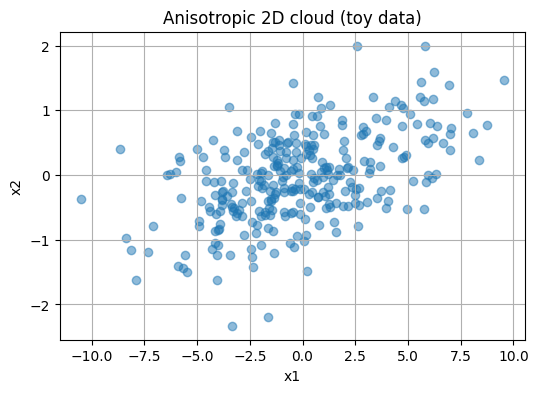

X_toy shape: (300, 2)


In [57]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
# Generate an anisotropic 2D cloud
n_points = 300
# Start with an isotropic Gaussian
X_iso = np.random.randn(n_points, 2)
# Apply a linear transform to stretch and rotate the cloud
A = np.array([[3.0, 2.0],
 [0.0, 0.7]])
# Try changing these numbers!
X_toy = X_iso @ A.T
# shape (n_points, 2)
fig, ax = plt.subplots()
ax.scatter(X_toy[:, 0], X_toy[:, 1], alpha=0.5)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Anisotropic 2D cloud (toy data)')
plt.show()
print(f'X_toy shape: {X_toy.shape}')

### 1.2 Fit PCA and inspect directionsNow let's fit PCA with 2 components on the centered toy data.👉 Your job:
- Run the cell and look at:
- the principal component directions (rows of `components_`),
- the explained variance ratio.
- Compare the printed directions to the cloud you saw above.
- Does PC1 point along the main long direction of the cloud?
- Is PC2 orthogonal (at right angles) to PC1?

In [58]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
# Center the data (very important for PCA!)
X_toy_centered = X_toy - X_toy.mean(axis=0, keepdims=True)
pca_2d = PCA(n_components=2, random_state=SEED)
pca_2d.fit(X_toy_centered)
print('PCA components (each row is a direction vector):')
print(pca_2d.components_)
print()
print('Explained variance ratio:', pca_2d.explained_variance_ratio_)
print('Sum of explained variance ratio:', pca_2d.explained_variance_ratio_.sum())

PCA components (each row is a direction vector):
[[ 0.99482053  0.10164697]
 [-0.10164697  0.99482053]]

Explained variance ratio: [0.97346558 0.02653442]
Sum of explained variance ratio: 1.0


- PC1 points along the main long direction of the cloud.
- `<PC1, PC2> = 0`, PC2 is orthogonal to PC1.

### 1.3 Visualize PCA directions as arrowsThe next cell overlays the first two PCA directions on top of the data cloud.👉 Your job:
- Run the cell.
- Adjust `arrow_scale` if needed so the arrows are easy to see.
- Check whether:
- PC1 lines up with the main direction of spread,
- PC2 is orthogonal to PC1.

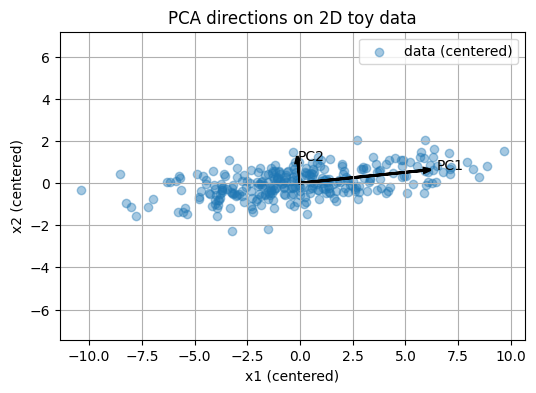

In [59]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
# Plot data with PCA directions (arrows from the mean)
arrow_scale = 6.0
# You can tweak this for visibility
mean_point = X_toy_centered.mean(axis=0)
fig, ax = plt.subplots()
ax.scatter(X_toy_centered[:, 0], X_toy_centered[:, 1], alpha=0.4, label='data (centered)')
for i, (vec, var_ratio) in enumerate(zip(pca_2d.components_, pca_2d.explained_variance_ratio_)):
      # Arrow length proportional to sqrt of explained variance (for visibility)
      length = np.sqrt(var_ratio) * arrow_scale
      ax.arrow(
          mean_point[0], mean_point[1],
          length * vec[0], length * vec[1],
          head_width=0.2, head_length=0.3,
          linewidth=2,
        )
      ax.text(
          mean_point[0] + length * vec[0] * 1.1,
          mean_point[1] + length * vec[1] * 1.1,
          f'PC{i+1}',
          fontsize=10,
        )
      ax.set_xlabel('x1 (centered)')
      ax.set_ylabel('x2 (centered)')
      ax.set_title('PCA directions on 2D toy data')
plt.legend()
plt.axis('equal')
plt.show()

### checked:
- PC1 is orthogonal to PC2
- PC1 lines up with the main direction of spread

### 1.4 Project onto the first principal componentPCA gives us a 1D coordinate along PC1 for each point.👉 Your job:
- Run the cell below to compute the PC1 coordinates and plot their histogram.
- Think: what information are we keeping vs discarding when we project from 2D to 1D?
- **keep: How data is stretched through x1. discard: most of x2**

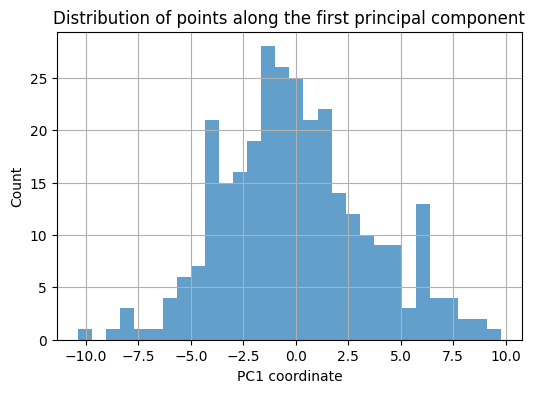

Original dimension: 2D
Projected dimension: 1D (PC1 only)


In [60]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
# Project centered data onto PC1
X_toy_pc1 = pca_2d.transform(X_toy_centered)[:, 0]
# first component only
fig, ax = plt.subplots()
ax.hist(X_toy_pc1, bins=30, alpha=0.7)
ax.set_xlabel('PC1 coordinate')
ax.set_ylabel('Count')
ax.set_title('Distribution of points along the first principal component')
plt.show()
print(f'Original dimension: {X_toy.shape[1]}D')
print('Projected dimension: 1D (PC1 only)')


---
## Core Task 2 — Logistic regression with and without PCA (digits dataset)Now we'll move to a more realistic setting:
- The `digits` dataset has 8×8 grayscale images of handwritten digits (0–9).
- Each image is flattened to 64 pixel features.
- We'll compare a logistic regression classifier:
- trained on raw pixels, vs.
- trained on PCA-compressed features.We will look at how test accuracy and explained variance change as we keep more components.

X shape: (1797, 64)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


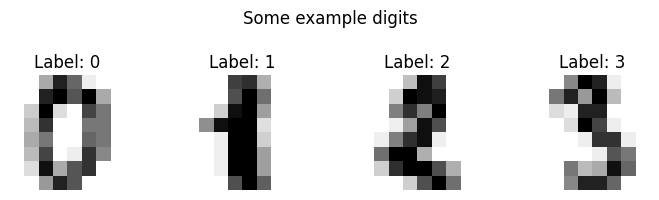

In [61]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
digits = load_digits()
X = digits.data
# shape (n_samples, 64)
y = digits.target
# digit labels 0–9
print('X shape:', X.shape)
print('Unique labels:', np.unique(y))
# Quick peek at a few digit images
fig, axes = plt.subplots(1, 4, figsize=(8, 2))
for ax, idx in zip(axes, range(4)):
  ax.imshow(digits.images[idx], cmap='gray_r')
  ax.set_title(f'Label: {y[idx]}')
  ax.axis('off')
  plt.suptitle('Some example digits')
  plt.tight_layout()
plt.show()

### 2.1 Train and test splitWe will create a standard train and test split.👉 Your job:
- Run the cell.
- Double-check the shapes and that the split sizes look reasonable.

In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y,
    )
print('Train shape:', X_train.shape, 'Labels:', y_train.shape)
print('Test  shape:', X_test.shape, 'Labels:', y_test.shape)

Train shape: (1437, 64) Labels: (1437,)
Test  shape: (360, 64) Labels: (360,)


### 2.2 Baseline: logistic regression on raw pixelsWe will build a simple `scikit-learn` pipeline:
1. `StandardScaler` standardizes each pixel feature.
2. `LogisticRegression` is a multi-class classifier.👉 Your job:
- Run the cell.
- Record the baseline train and test accuracy.
- Think: are we clearly overfitting, underfitting, or somewhere in between?

In [63]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
baseline_clf = Pipeline([
    ('scaler', StandardScaler()),
     ('logreg', LogisticRegression(
         max_iter=1000,
         n_jobs=-1,
         random_state=SEED,
         )),
    ])
baseline_clf.fit(X_train, y_train)
y_train_pred = baseline_clf.predict(X_train)
y_test_pred = baseline_clf.predict(X_test)
baseline_train_acc = accuracy_score(y_train, y_train_pred)
baseline_test_acc = accuracy_score(y_test, y_test_pred)
print('Baseline logistic regression (no PCA)')
print(f'  Train accuracy: {baseline_train_acc:.3f}')
print(f'   Test accuracy: {baseline_test_acc:.3f}')
y_test_pred_logistic = y_test_pred

Baseline logistic regression (no PCA)
  Train accuracy: 0.999
   Test accuracy: 0.975


### 2.3 Logistic regression with PCANow we will insert PCA into the pipeline:`StandardScaler -> PCA -> LogisticRegression`We will try different numbers of components and see how:
- the cumulative explained variance (how much energy we keep),
- and the test accuracy,change as we compress more or less.👉 Your job:
- Run the cell as is to get a first set of results.
- Then edit `n_components_list` to explore other values, for example `[2, 5, 10, 20, 30, 40, 50]`.
- Look for a sweet spot where we keep enough variance for good accuracy, without using all 64 dimensions.

In [64]:
n_components_list = [2, 5, 10, 20, 40]
# Feel free to edit this list!
rows = []
for n_components in n_components_list:
  clf = Pipeline([
      ('scaler', StandardScaler()),
       ('pca', PCA(n_components=n_components, random_state=SEED)),
        ('logreg', LogisticRegression(
            max_iter=1000,
            n_jobs=-1,
            random_state=SEED,
            )),
      ])
  clf.fit(X_train, y_train)
  y_test_pred = clf.predict(X_test)
  test_acc = accuracy_score(y_test, y_test_pred)
  explained = clf.named_steps['pca'].explained_variance_ratio_.sum()
  rows.append({
      'n_components': n_components,
      'explained_variance_ratio_sum': explained,
      'test_accuracy': test_acc,
      })
results_df = pd.DataFrame(rows).sort_values('n_components')
results_df

,n_components,explained_variance_ratio_sum,test_accuracy
0,2,0.221321,0.563889
1,5,0.422675,0.797222
2,10,0.595690,0.863889
3,20,0.788938,0.952778
4,40,0.954230,0.961111


### 2.4 Plotting accuracy versus number of componentsThe table is helpful, but a plot makes the pattern clearer.👉 Your job:
- Run the cell.
- Describe in words (in a new markdown cell, or to a neighbour) how test accuracy and explained variance change with `n_components`.
- Compare to the baseline (no PCA) test accuracy.

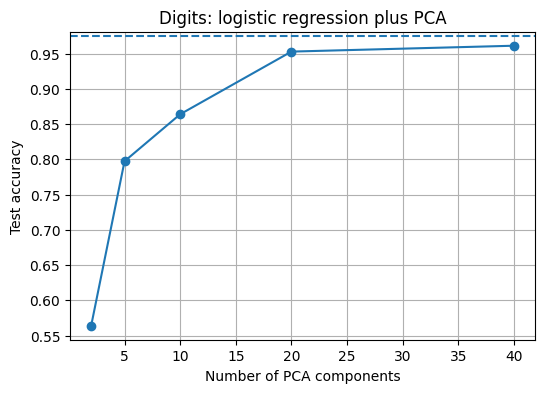

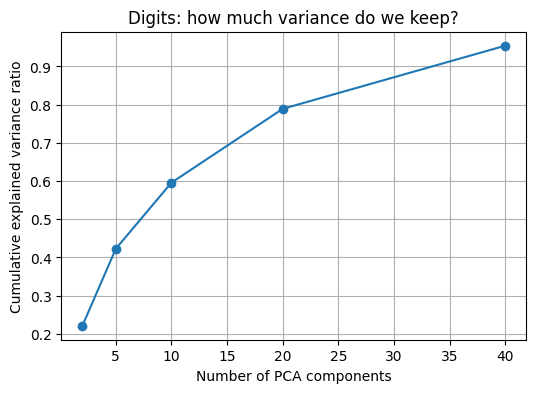

Baseline (no PCA) test accuracy: 0.975


In [65]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
fig, ax = plt.subplots()
ax.plot(results_df['n_components'], results_df['test_accuracy'], marker='o')
ax.axhline(baseline_test_acc, linestyle='--')
ax.set_xlabel('Number of PCA components')
ax.set_ylabel('Test accuracy')
ax.set_title('Digits: logistic regression plus PCA')
plt.show()
fig, ax = plt.subplots()
ax.plot(results_df['n_components'], results_df['explained_variance_ratio_sum'], marker='o')
ax.set_xlabel('Number of PCA components')
ax.set_ylabel('Cumulative explained variance ratio')
ax.set_title('Digits: how much variance do we keep?')
plt.show()
print(f'Baseline (no PCA) test accuracy: {baseline_test_acc:.3f}')


---
## Stretch goals (if you have extra time)These are optional but good for deeper understanding.
### Stretch 1 — Visualizing PCA reconstructionsPCA does not just compress; we can also approximately reconstruct the original data from a reduced representation.The cell below:
- fits PCA on centered training data,
- projects some test images into a low-dimensional space,
- reconstructs them back to 64 dimensions,
- and shows original versus reconstructed digits.👉 Your job:
- Run the cell for different values of `n_components_recon` (for example 5, 10, 20, 40).
- Visually compare how much detail we lose as we compress more aggressively.

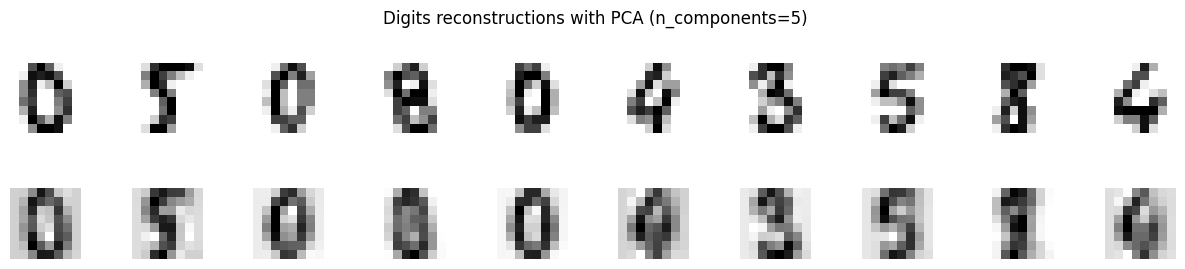

In [66]:
# NOTE: automatic formatting skipped for this cell due to syntax error during rewrite.
# You can change this and re-run the cell
n_components_recon = 5
# Center based on training data
train_mean = X_train.mean(axis=0, keepdims=True)
X_train_centered = X_train - train_mean
X_test_centered = X_test - train_mean
pca_recon = PCA(n_components=n_components_recon, random_state=SEED)
pca_recon.fit(X_train_centered)
# Project and reconstruct some test examples
n_examples = 10
X_test_sample = X_test_centered[:n_examples]
X_test_sample_pca = pca_recon.transform(X_test_sample)
X_test_sample_recon_centered = pca_recon.inverse_transform(X_test_sample_pca)
X_test_sample_recon = X_test_sample_recon_centered + train_mean
fig, axes = plt.subplots(2, n_examples, figsize=(1.2 * n_examples, 3))
for i in range(n_examples):
  # Original
  axes[0, i].imshow(X_test[:n_examples][i].reshape(8, 8), cmap='gray_r')
  axes[0, i].axis('off')
  if i == 0:
    axes[0, i].set_ylabel('Original', fontsize=10)
  # Reconstructed
  axes[1, i].imshow(X_test_sample_recon[i].reshape(8, 8), cmap='gray_r')
  axes[1, i].axis('off')
  if i == 0:
      axes[1, i].set_ylabel('Recon', fontsize=10)
      plt.suptitle(f'Digits reconstructions with PCA (n_components={n_components_recon})')
      plt.tight_layout()

plt.show()

### Stretch 2 — Where does PCA help or hurt?Ideas to explore (pick one):
- Look at the confusion matrix for:
- baseline logistic regression,
- a PCA-compressed model with relatively few components.
- Are there particular digits that become more easily confused when we compress too aggressively?
- Try measuring not just accuracy, but also something like macro averaged F1 (see `sklearn.metrics.f1_score`).If you try this, add one short markdown cell summarizing what you found.

In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_logistic = confusion_matrix(y_test, y_test_pred_logistic)


print('confusion matrix for logistic: ')
print(cm_logistic)

cm_pca = confusion_matrix(y_test, y_test_pred)


print('confusion matrix for pca: ')
print(cm_pca)



confusion matrix for logistic: 
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  1  0  0  0  0  0]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  1 35  0  1  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 36  0  0  0  0]
 [ 0  0  0  0  0  1 34  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  3  0  0  0  0  0  0 32  0]
 [ 0  0  0  0  0  0  0  0  0 36]]
confusion matrix for pca: 
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  1  0]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  2 34  0  1  0  0  0  0]
 [ 0  1  0  0 35  0  0  0  0  0]
 [ 0  0  0  0  0 36  0  0  0  0]
 [ 0  0  0  0  1  0 34  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  3  0  0  0  1  0  0 31  0]
 [ 0  1  0  0  0  1  0  0  0 34]]


- The fourth digit, `8`, become more easily confused when compress too aggresively.